In [1]:
# Some common data manipulation imports
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import LSTM, Dense
from tensorflow import keras
from keras.optimizers import Adam
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.preprocessing.image import ImageDataGenerator
import time
from keras.callbacks import TensorBoard
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, plot_confusion_matrix
import csv
from keras.utils.vis_utils import plot_model
from keras.callbacks import History
from matplotlib import pyplot as plt
#normalizing the data
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from pandas import DataFrame
from sklearn.metrics import classification_report, confusion_matrix
import time
from keras.preprocessing.sequence import TimeseriesGenerator

#some other imports
import os
pd.set_option('display.max_rows', 100000)

# For stable output on each run
np.random.seed(3)

# To plot easily visible pictures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

Using TensorFlow backend.


In [2]:
original = pd.read_csv('100_nodes.csv')
original = original[['date', 'name', 'target']]
#train, test = train_test_split(original, test_size=0.2)

In [3]:
temp = original[(original['name'] == 51)]
times = temp[['date', 'target']]
times.set_axis(times['date'], inplace=True)
#times.drop(['date'], axis=1, inplace=True)

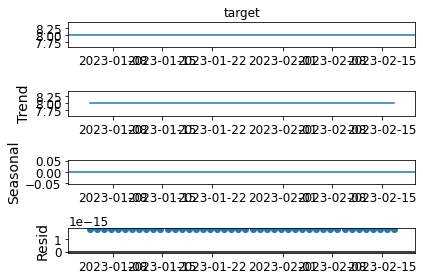

<Figure size 1440x1440 with 0 Axes>

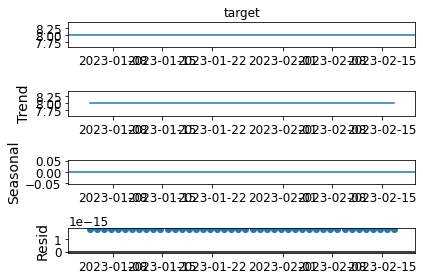

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose
times.index = pd.to_datetime(times.index)
times.index.freq = pd.infer_freq(times.index)
results = seasonal_decompose(times['target'].iloc[0:50])
plt.figure(figsize = (20,20))
results.plot()

In [5]:
# Create rolling average
rolling_avg = times['target'].rolling(window=7).mean()

# Subtract rolling average from original data to make it stationary
stationary_data = times['target'] - rolling_avg

t_data = stationary_data.values

# t_data = times['target'].values
# Take first difference to make data stationary
# t_data = np.diff(t_data)
# t_data = np.diff(t_data)
# t_data = np.diff(t_data)
t_data = np.absolute(t_data)
print(t_data)
t_data = t_data.reshape((-1,1))
#print(t_data)

split_percent = 0.80
split = int(split_percent * len(t_data))
print(split)

t_train = t_data[6:split]
t_test = t_data[split:]
print(t_train)

date_train = times['date'][6:split]
date_test = times['date'][split:]

scaler = MinMaxScaler()
t_train = scaler.fit_transform(t_train)
t_test = scaler.transform(t_test)

[nan nan nan ...  0.  0.  0.]
876
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]


In [6]:
look_back = 200
#3 = 2.4842117019480376
train_generator = TimeseriesGenerator(t_train, t_train, length=look_back, batch_size=64)     
test_generator = TimeseriesGenerator(t_test, t_test, length=look_back, batch_size=1)

In [7]:
model=Sequential()
# # watch out for return_sequence
model.add(LSTM(10,activation='relu',input_shape=(look_back, 1),return_sequences=True))
model.add(Dropout(0.2))
# model.add(LSTM(128,activation='relu',return_sequences=True))
# model.add(Dropout(0.2))
# model.add(LSTM(512,activation='relu',return_sequences=True))
# model.add(Dropout(0.2))
# model.add(LSTM(128,activation='relu',return_sequences=True))
# model.add(Dropout(0.2))
model.add(LSTM(10,activation='relu'))
model.add(Dense(128))
model.add(Dropout(0.2))
model.add(Dense(1))
opt= Adam(lr=.01)
model.compile(optimizer=opt,loss='mse')
model.summary()
model.fit(train_generator, epochs=50, verbose=1)

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
lstm_1 (LSTM)                (None, 200, 10)           480       
_________________________________________________________________
dropout_1 (Dropout)          (None, 200, 10)           0         
_________________________________________________________________
lstm_2 (LSTM)                (None, 10)                840       
_________________________________________________________________
dense_1 (Dense)              (None, 128)               1408      
_________________________________________________________________
dropout_2 (Dropout)          (None, 128)               0         
_________________________________________________________________
dense_2 (Dense)              (None, 1)                 129       
Total params: 2,857
Trainable params: 2,857
Non-trainable params: 0
____________________________________________________

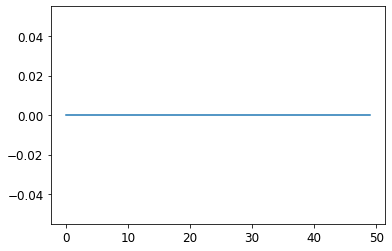

In [8]:
loss_per_epoch = model.history.history['loss']
plt.plot(range(len(loss_per_epoch)),loss_per_epoch)

In [9]:
last_train_batch = t_train[-(look_back):]
last_train_batch = last_train_batch.reshape((1, look_back, 1))
model.predict(last_train_batch)   
# array([[0.6046513]], dtype=float32)

array([[0.]], dtype=float32)

In [10]:
t_test[0]

array([0.])

In [11]:
test_predictions = []
n_features = 1

first_eval_batch = t_train[-(look_back):]
current_batch = first_eval_batch.reshape((1, look_back, n_features))

for i in range(len(t_test)):
    
    # get the prediction value for the first batch
    current_pred = model.predict(current_batch)[0]
    
    # append the prediction into the array
    test_predictions.append(current_pred) 
    
    # use the prediction to update the batch and remove the first value
    current_batch = np.append(current_batch[:,1:,:],[[current_pred]],axis=1)

In [12]:
test_predictions

[array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], dtype=float32),
 array([0.], d

In [13]:
# from sklearn.metrics import r2_score
# i = 0
# prediction = model.predict_generator(test_generator)
# prediction = scaler.inverse_transform(prediction)
# t_test_t = scaler.inverse_transform(t_test)
# rmse = np.sqrt(np.mean((prediction - t_test_t[-(219 - look_back):]) ** 2))
# print(f'Node {i}: RMSE = {rmse}')
# mape = np.mean(np.abs((t_test_t[-(219 - look_back):] - prediction) / t_test_t[-(219 - look_back):])) * 100
# print(f'Node {i}: MAPE = {mape}')
# r2 = r2_score(t_test_t[-(219 - look_back):], prediction)
# print(f'Node {i}: R2 = {r2}')

In [14]:
# prediction

In [15]:
# for i in range(len(test_generator)):
#     x, y = test_generator[i]
#     print('Batch', i+1)
#     print('X:', x)
#     print('Y:', y)

In [16]:
# t_test

In [17]:
# plt.plot(t_train[0:100])
t_test

array([[0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],

<AxesSubplot:>

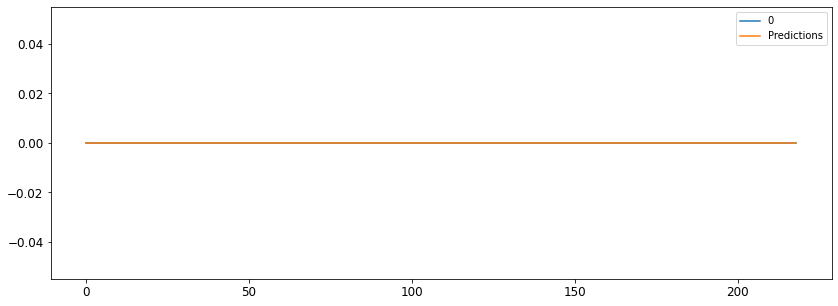

In [18]:
true_predictions = scaler.inverse_transform(test_predictions)
test = scaler.inverse_transform(t_test)   
test = pd.DataFrame(test)
test['Predictions'] = true_predictions
     

test.plot(figsize=(14,5))

In [19]:
test

,0,Predictions
0,0.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,0.0
5,0.0,0.0
6,0.0,0.0
7,0.0,0.0
8,0.0,0.0
9,0.0,0.0


In [20]:
from sklearn.metrics import mean_squared_error
from math import sqrt
rmse=sqrt(mean_squared_error(test['target'],test['Predictions']))
print(rmse)

KeyError: 'target'

In [ ]:
t_train